# DSCI 552 — Homework 5

Name: Zhicheng Zhang  
GitHub Username: Hustzz-Max  
USC ID: 8006795737

## 1. Decision Trees as Interpretable Models

### 1(a). Load the data

120 rows, six features, two labels. 0 = no; 1 = yes.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_score, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, mean_squared_error
from xgboost import XGBRegressor

data_dir = Path('../data')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_rows', 130)

acute_columns = [
    'temperature', 'nausea', 'lumbar_pain', 'urine_pushing',
    'micturition_pain', 'burning', 'bladder', 'nephritis'
]
acute = pd.read_csv(
    data_dir / 'diagnosis.data', sep='\t', header=None,
    names=acute_columns, encoding='utf-16', decimal=','
)
acute[acute_columns[1:]] = acute[acute_columns[1:]].replace(
    {'no': 0, 'yes': 1}
).astype(int)
print('Shape:', acute.shape)
print('Missing values:', acute.isna().sum().sum())
display(acute.head())

Shape: (120, 8)
Missing values: 0


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pain,burning,bladder,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


### 1(b). Fit and plot the full tree

Label powerset combines both diagnoses: 1|0 means bladder=yes, nephritis=no.
It keeps label links but is not always better than separate trees.

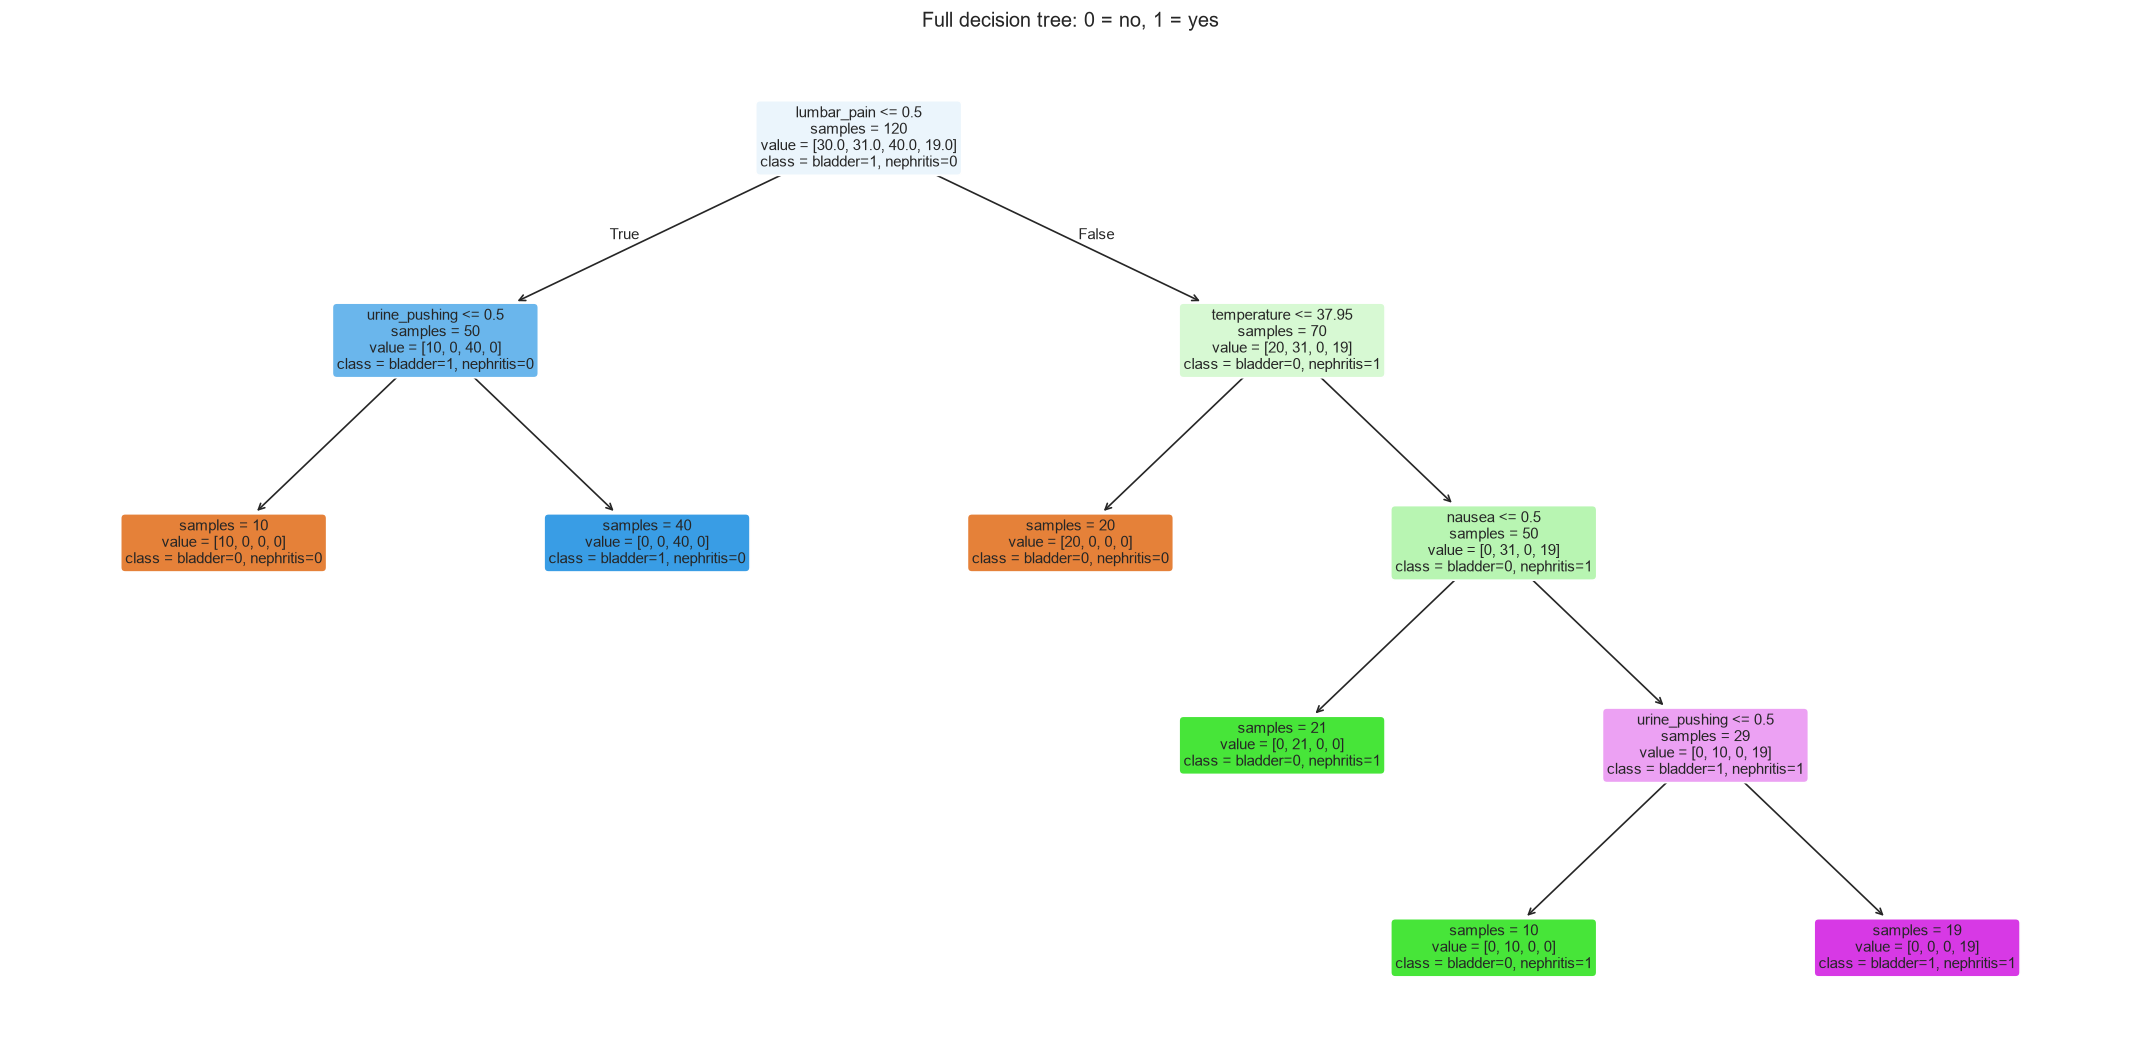

Depth: 4
Leaves: 6
Training accuracy: 1.0


In [2]:
X_acute = acute[acute_columns[:6]]
y_acute = acute[['bladder', 'nephritis']].astype(str).agg('|'.join, axis=1)
full_tree = DecisionTreeClassifier(random_state=42)
full_tree.fit(X_acute, y_acute)

class_labels = []
for label in full_tree.classes_:
    bladder, nephritis = label.split('|')
    class_labels.append(f'bladder={bladder}, nephritis={nephritis}')

plt.figure(figsize=(18, 9))
plot_tree(
    full_tree, feature_names=list(X_acute.columns),
    class_names=class_labels, filled=True, rounded=True,
    impurity=False, proportion=False, fontsize=9
)
plt.title('Full decision tree: 0 = no, 1 = yes')
plt.tight_layout()
plt.show()
print('Depth:', full_tree.get_depth())
print('Leaves:', full_tree.get_n_leaves())
print('Training accuracy:', round(full_tree.score(X_acute, y_acute), 4))

### 1(c). IF-THEN rules

In [3]:
def get_rules(model, feature_names):
    tree = model.tree_
    rules = []

    def visit(node, conditions):
        if tree.children_left[node] == tree.children_right[node]:
            label = model.classes_[np.argmax(tree.value[node][0])]
            bladder, nephritis = label.split('|')
            bladder = 'yes' if bladder == '1' else 'no'
            nephritis = 'yes' if nephritis == '1' else 'no'
            condition = ' AND '.join(conditions) if conditions else 'TRUE'
            rules.append(
                f'IF {condition} THEN bladder={bladder}, nephritis={nephritis}.'
            )
        else:
            name = feature_names[tree.feature[node]]
            threshold = tree.threshold[node]
            if name == 'temperature':
                left = f'{name} <= {threshold:.2f}'
                right = f'{name} > {threshold:.2f}'
            else:
                left = f'{name}=no'
                right = f'{name}=yes'
            visit(tree.children_left[node], conditions + [left])
            visit(tree.children_right[node], conditions + [right])

    visit(0, [])
    return rules

for number, rule in enumerate(get_rules(full_tree, list(X_acute.columns)), 1):
    print(f'{number}. {rule}')

1. IF lumbar_pain=no AND urine_pushing=no THEN bladder=no, nephritis=no.
2. IF lumbar_pain=no AND urine_pushing=yes THEN bladder=yes, nephritis=no.
3. IF lumbar_pain=yes AND temperature <= 37.95 THEN bladder=no, nephritis=no.
4. IF lumbar_pain=yes AND temperature > 37.95 AND nausea=no THEN bladder=no, nephritis=yes.
5. IF lumbar_pain=yes AND temperature > 37.95 AND nausea=yes AND urine_pushing=no THEN bladder=no, nephritis=yes.
6. IF lumbar_pain=yes AND temperature > 37.95 AND nausea=yes AND urine_pushing=yes THEN bladder=yes, nephritis=yes.


### 1(d). Cost-complexity pruning

Five-fold CV compares pruning strengths. We also show the best smaller tree.
Both trees use all 120 rows; there is no separate test set.

,alpha,leaves,depth,training_accuracy,CV_accuracy
0,0.000000,6,4,1.000000,0.991667
1,0.098167,4,2,0.841667,0.858333
2,0.133333,3,2,0.758333,0.758333
3,0.182000,2,1,0.591667,0.666667
4,0.222917,1,0,0.333333,0.483333


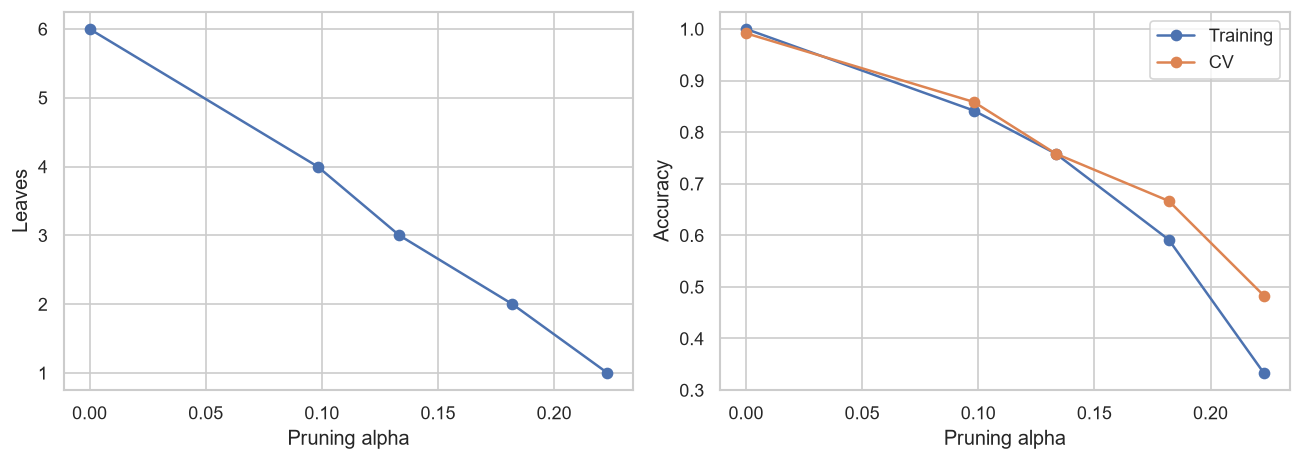

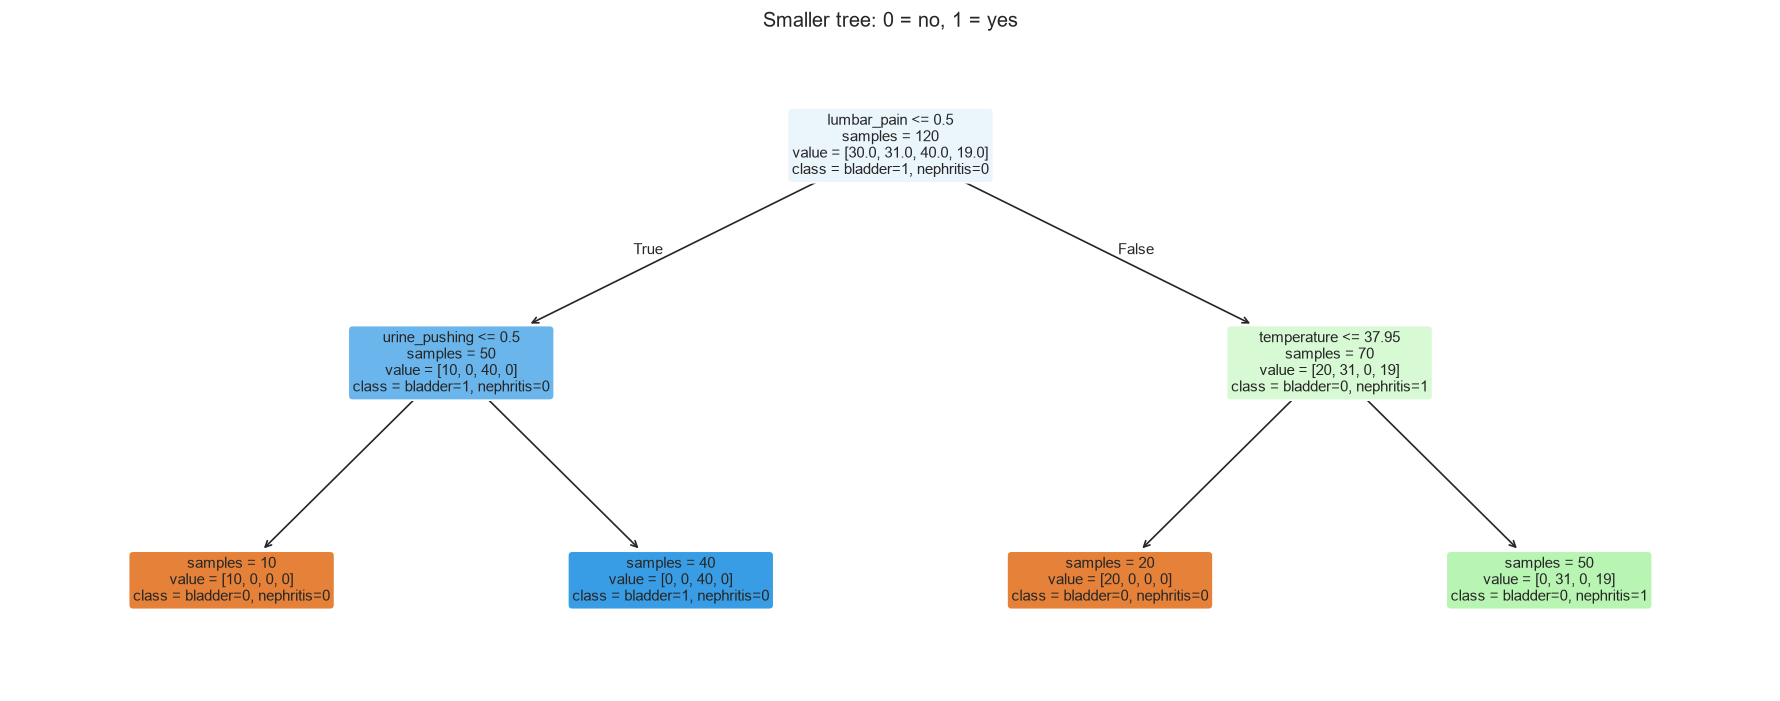

Best CV tree: 6 leaves, CV accuracy = 0.9917
Smaller tree: alpha = 0.098167, leaves = 4
Smaller tree training accuracy: 0.8417
Smaller tree CV accuracy: 0.8583
1. IF lumbar_pain=no AND urine_pushing=no THEN bladder=no, nephritis=no.
2. IF lumbar_pain=no AND urine_pushing=yes THEN bladder=yes, nephritis=no.
3. IF lumbar_pain=yes AND temperature <= 37.95 THEN bladder=no, nephritis=no.
4. IF lumbar_pain=yes AND temperature > 37.95 THEN bladder=no, nephritis=yes.


In [4]:
tree_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pruning_path = full_tree.cost_complexity_pruning_path(X_acute, y_acute)
tree_rows = []

for alpha in np.unique(pruning_path.ccp_alphas):
    model = DecisionTreeClassifier(random_state=42, ccp_alpha=alpha)
    scores = cross_val_score(model, X_acute, y_acute, cv=tree_cv, scoring='accuracy')
    model.fit(X_acute, y_acute)
    tree_rows.append({
        'alpha': alpha,
        'leaves': model.get_n_leaves(),
        'depth': model.get_depth(),
        'training_accuracy': model.score(X_acute, y_acute),
        'CV_accuracy': scores.mean()
    })

pruning_results = pd.DataFrame(tree_rows)
display(pruning_results.round(6))
best_tree_row = pruning_results.sort_values(
    ['CV_accuracy', 'leaves'], ascending=[False, True]
).iloc[0]
smaller_trees = pruning_results[
    (pruning_results['leaves'] < full_tree.get_n_leaves()) &
    (pruning_results['leaves'] > 1)
]
compact_row = smaller_trees.sort_values(
    ['CV_accuracy', 'leaves'], ascending=[False, True]
).iloc[0]
compact_tree = DecisionTreeClassifier(random_state=42, ccp_alpha=compact_row['alpha'])
compact_tree.fit(X_acute, y_acute)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(pruning_results['alpha'], pruning_results['leaves'], 'o-')
axes[0].set_xlabel('Pruning alpha')
axes[0].set_ylabel('Leaves')
axes[1].plot(pruning_results['alpha'], pruning_results['training_accuracy'], 'o-', label='Training')
axes[1].plot(pruning_results['alpha'], pruning_results['CV_accuracy'], 'o-', label='CV')
axes[1].set_xlabel('Pruning alpha')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 6))
plot_tree(
    compact_tree, feature_names=list(X_acute.columns), class_names=class_labels,
    filled=True, rounded=True, impurity=False, fontsize=9
)
plt.title('Smaller tree: 0 = no, 1 = yes')
plt.tight_layout()
plt.show()

print(f'Best CV tree: {int(best_tree_row["leaves"])} leaves, CV accuracy = {best_tree_row["CV_accuracy"]:.4f}')
print(f'Smaller tree: alpha = {compact_row["alpha"]:.6f}, leaves = {compact_tree.get_n_leaves()}')
print(f'Smaller tree training accuracy: {compact_tree.score(X_acute, y_acute):.4f}')
print(f'Smaller tree CV accuracy: {compact_row["CV_accuracy"]:.4f}')
for number, rule in enumerate(get_rules(compact_tree, list(X_acute.columns)), 1):
    print(f'{number}. {rule}')

Pruning reduces 6 rules to 4, but CV accuracy falls from 0.9917 to 0.8583.

## 2. The LASSO and Boosting for Regression

### 2(a). Load and split the data

Training: first 1495 rows. Testing: last 499 rows. Target: ViolentCrimesPerPop.

Source: [UCI](https://archive.ics.uci.edu/dataset/183/communities+and+crime).

In [5]:
name_lines = (data_dir / 'communities.names').read_text().splitlines()
crime_columns = [
    line.split()[1] for line in name_lines
    if line.lower().startswith('@attribute')
]
crime = pd.read_csv(
    data_dir / 'communities.data', header=None,
    names=crime_columns, na_values='?'
)
train = crime.iloc[:1495].copy()
test = crime.iloc[1495:].copy()
target = 'ViolentCrimesPerPop'
print('Full data:', crime.shape)
print('Training rows:', len(train))
print('Test rows:', len(test))
display(crime.head())

Full data: (1994, 128)
Training rows: 1495
Test rows: 499


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,numbUrban,pctUrban,medIncome,pctWWage,pctWFarmSelf,pctWInvInc,pctWSocSec,pctWPubAsst,pctWRetire,medFamInc,perCapInc,whitePerCap,blackPerCap,indianPerCap,AsianPerCap,OtherPerCap,HispPerCap,NumUnderPov,PctPopUnderPov,PctLess9thGrade,PctNotHSGrad,PctBSorMore,PctUnemployed,PctEmploy,PctEmplManu,PctEmplProfServ,PctOccupManu,PctOccupMgmtProf,MalePctDivorce,MalePctNevMarr,FemalePctDiv,TotalPctDiv,PersPerFam,PctFam2Par,PctKids2Par,PctYoungKids2Par,PctTeen2Par,PctWorkMomYoungKids,PctWorkMom,NumIlleg,PctIlleg,NumImmig,PctImmigRecent,PctImmigRec5,PctImmigRec8,PctImmigRec10,PctRecentImmig,PctRecImmig5,PctRecImmig8,PctRecImmig10,PctSpeakEnglOnly,PctNotSpeakEnglWell,PctLargHouseFam,PctLargHouseOccup,PersPerOccupHous,PersPerOwnOccHous,PersPerRentOccHous,PctPersOwnOccup,PctPersDenseHous,PctHousLess3BR,MedNumBR,HousVacant,PctHousOccup,PctHousOwnOcc,PctVacantBoarded,PctVacMore6Mos,MedYrHousBuilt,PctHousNoPhone,PctWOFullPlumb,OwnOccLowQuart,OwnOccMedVal,OwnOccHiQuart,RentLowQ,RentMedian,RentHighQ,MedRent,MedRentPctHousInc,MedOwnCostPctInc,MedOwnCostPctIncNoMtg,NumInShelters,NumStreet,PctForeignBorn,PctBornSameState,PctSameHouse85,PctSameCity85,PctSameState85,LemasSwornFT,LemasSwFTPerPop,LemasSwFTFieldOps,LemasSwFTFieldPerPop,LemasTotalReq,LemasTotReqPerPop,PolicReqPerOffic,PolicPerPop,RacialMatchCommPol,PctPolicWhite,PctPolicBlack,PctPolicHisp,PctPolicAsian,PctPolicMinor,OfficAssgnDrugUnits,NumKindsDrugsSeiz,PolicAveOTWorked,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,0.17,0.34,0.47,0.29,0.32,0.20,1.0,0.37,0.72,0.34,0.60,0.29,0.15,0.43,0.39,0.40,0.39,0.32,0.27,0.27,0.36,0.41,0.08,0.19,0.10,0.18,0.48,0.27,0.68,0.23,0.41,0.25,0.52,0.68,0.40,0.75,0.75,0.35,0.55,0.59,0.61,0.56,0.74,0.76,0.04,0.14,0.03,0.24,0.27,0.37,0.39,0.07,0.07,0.08,0.08,0.89,0.06,0.14,0.13,0.33,0.39,0.28,0.55,0.09,0.51,0.5,0.21,0.71,0.52,0.05,0.26,0.65,0.14,0.06,0.22,0.19,0.18,0.36,0.35,0.38,0.34,0.38,0.46,0.25,0.04,0.0,0.12,0.42,0.50,0.51,0.64,0.03,0.13,0.96,0.17,0.06,0.18,0.44,0.13,0.94,0.93,0.03,0.07,0.1,0.07,0.02,0.57,0.29,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,0.02,1.0,0.31,0.72,0.11,0.45,0.25,0.29,0.39,0.29,0.37,0.38,0.33,0.16,0.30,0.22,0.35,0.01,0.24,0.14,0.24,0.30,0.27,0.73,0.57,0.15,0.42,0.36,1.00,0.63,0.91,1.00,0.29,0.43,0.47,0.60,0.39,0.46,0.53,0.00,0.24,0.01,0.52,0.62,0.64,0.63,0.25,0.27,0.25,0.23,0.84,0.10,0.16,0.10,0.17,0.29,0.17,0.26,0.20,0.82,0.0,0.02,0.79,0.24,0.02,0.25,0.65,0.16,0.00,0.21,0.20,0.21,0.42,0.38,0.40,0.37,0.29,0.32,0.18,0.00,0.0,0.21,0.50,0.34,0.60,0.52,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,0.00,0.0,0.30,0.58,0.19,0.39,0.38,0.40,0.84,0.28,0.27,0.29,0.27,0.07,0.29,0.28,0.39,0.01,0.27,0.27,0.43,0.19,0.36,0.58,0.32,0.29,0.49,0.32,0.63,0.41,0.71,0.70,0.45,0.42,0.44,0.43,0.43,0.71,0.67,0.01,0.46,0.00,0.07,0.06,0.15,0.19,0.02,0.02,0.04,0.05,0.88,0.04,0.20,0.20,0.46,0.52,0.43,0.42,0.15,0.51,0.5,0.01,0.86,0.41,0.29,0.30,0.52,0.47,0.45,0.18,0.17,0.16,0.27,0.29,0.27,0.31,0.48,0.39,0.28,0.00,0.0,0.14,0.49,0.54,0.67,0.56,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,0.10,0.51,0.50,0.34,0.21,0.06,1.0,0.58,0.89,0.21,0.43,0.36,0.20,0.82,0.51,0.36,0.40,0.39,0.16,0.25,0.36,0.44,0.01,0.10,0.09,0.25,0.31,0.33,0.71,0.36,0.45,0.37,0.39,0.34,0.45,0.49,0.44,0.75,0.65,0.54,0.83,0.65,0.85,0.86,0.03,0.33,0.02,0.11,0.20,0.30,0.31,0.05,0.08,0.11,0.11,0.81,0.08,0.56,0.62,0.85,0.77,1.00,0.94,0.1

### 2(b). Remove ID features and fill missing values

Remove the five ID fields; keep 122 predictors. Fill missing values with training medians.
Each CV fold fits its own imputer.

In [6]:
id_columns = ['state', 'county', 'community', 'communityname', 'fold']
X_train = train.drop(columns=id_columns + [target]).astype(float)
X_test = test.drop(columns=id_columns + [target]).astype(float)
y_train = train[target].astype(float)
y_test = test[target].astype(float)

missing = pd.DataFrame({
    'training_missing': X_train.isna().sum(),
    'test_missing': X_test.isna().sum()
})
display(missing.loc[missing.sum(axis=1) > 0])
imputer = SimpleImputer(strategy='median')
X_train_filled = pd.DataFrame(
    imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index
)
X_test_filled = pd.DataFrame(
    imputer.transform(X_test), columns=X_test.columns, index=X_test.index
)
print('Predictors:', X_train.shape[1])
print('Training missing values after imputation:', X_train_filled.isna().sum().sum())
print('Test missing values after imputation:', X_test_filled.isna().sum().sum())
cv = KFold(n_splits=5, shuffle=True, random_state=42)
results = []

,training_missing,test_missing
OtherPerCap,1,0
LemasSwornFT,1256,419
LemasSwFTPerPop,1256,419
LemasSwFTFieldOps,1256,419
LemasSwFTFieldPerPop,1256,419
LemasTotalReq,1256,419
LemasTotReqPerPop,1256,419
PolicReqPerOffic,1256,419
PolicPerPop,1256,419
RacialMatchCommPol,1256,419


Predictors: 122
Training missing values after imputation: 0
Test missing values after imputation: 0


### 2(c). Feature correlation matrix

Training data only. Several features are strongly correlated.

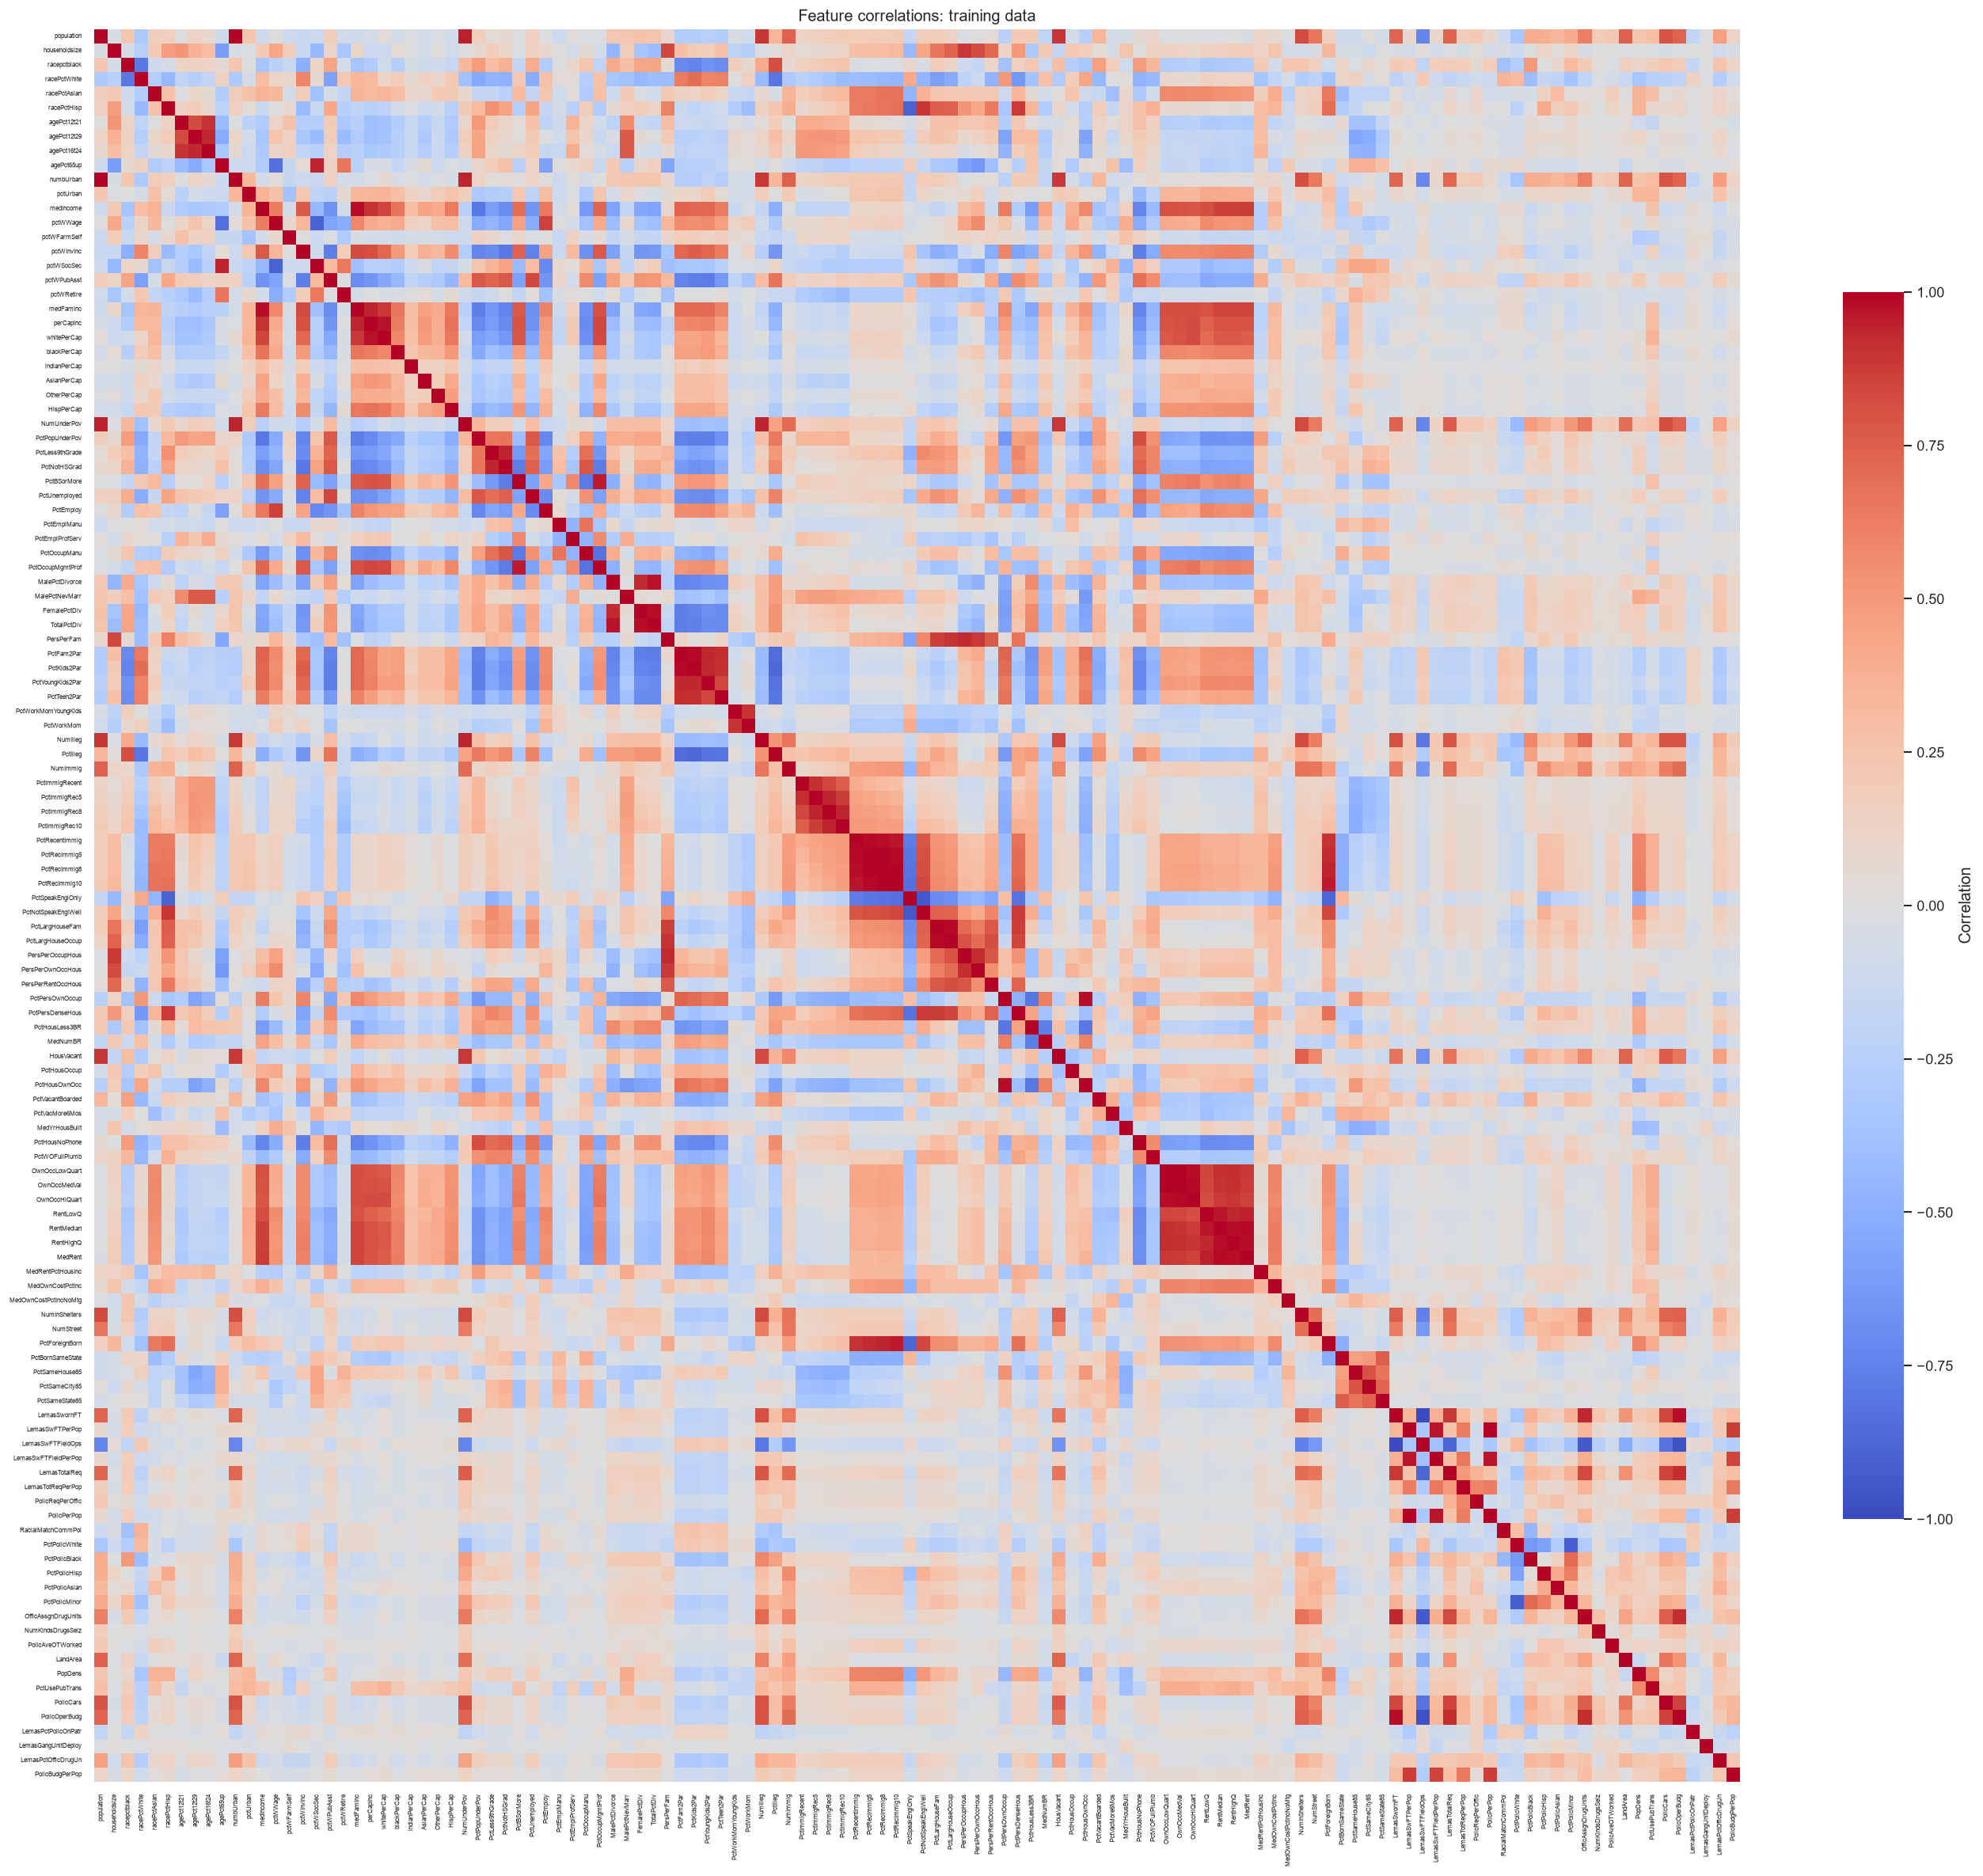

In [7]:
correlation = X_train_filled.corr()
plt.figure(figsize=(23, 20))
sns.heatmap(
    correlation, cmap='coolwarm', center=0, vmin=-1, vmax=1,
    xticklabels=True, yticklabels=True, cbar_kws={'label': 'Correlation', 'shrink': 0.7}
)
plt.xticks(rotation=90, fontsize=5)
plt.yticks(rotation=0, fontsize=5)
plt.title('Feature correlations: training data')
plt.tight_layout()
plt.show()

### 2(d). Coefficient of variation

CV = sample standard deviation / mean, using training data and ddof=1.

In [8]:
feature_means = X_train_filled.mean()
feature_std = X_train_filled.std(ddof=1)
variation = feature_std / feature_means.replace(0, np.nan)
cv_table = pd.DataFrame({
    'mean': feature_means,
    'sample_std': feature_std,
    'CV': variation
}).sort_values('CV', ascending=False)
display(cv_table.round(6))

,mean,sample_std,CV
PctPolicAsian,0.016254,0.089838,5.527059
NumStreet,0.022983,0.098665,4.292923
NumInShelters,0.029599,0.102736,3.470952
NumIlleg,0.037204,0.113806,3.058964
NumImmig,0.030595,0.089541,2.926635
LemasPctOfficDrugUn,0.093304,0.238201,2.552946
NumUnderPov,0.056849,0.133167,2.342443
LemasSwornFT,0.028749,0.064629,2.248042
population,0.058167,0.130359,2.241105
numbUrban,0.064649,0.131784,2.038461


### 2(e). Features with the highest CV

Select floor(sqrt(128)) = 11 predictors. Plots alone cannot prove significance.

,mean,sample_std,CV
PctPolicAsian,0.016254,0.089838,5.527059
NumStreet,0.022983,0.098665,4.292923
NumInShelters,0.029599,0.102736,3.470952
NumIlleg,0.037204,0.113806,3.058964
NumImmig,0.030595,0.089541,2.926635
LemasPctOfficDrugUn,0.093304,0.238201,2.552946
NumUnderPov,0.056849,0.133167,2.342443
LemasSwornFT,0.028749,0.064629,2.248042
population,0.058167,0.130359,2.241105
numbUrban,0.064649,0.131784,2.038461


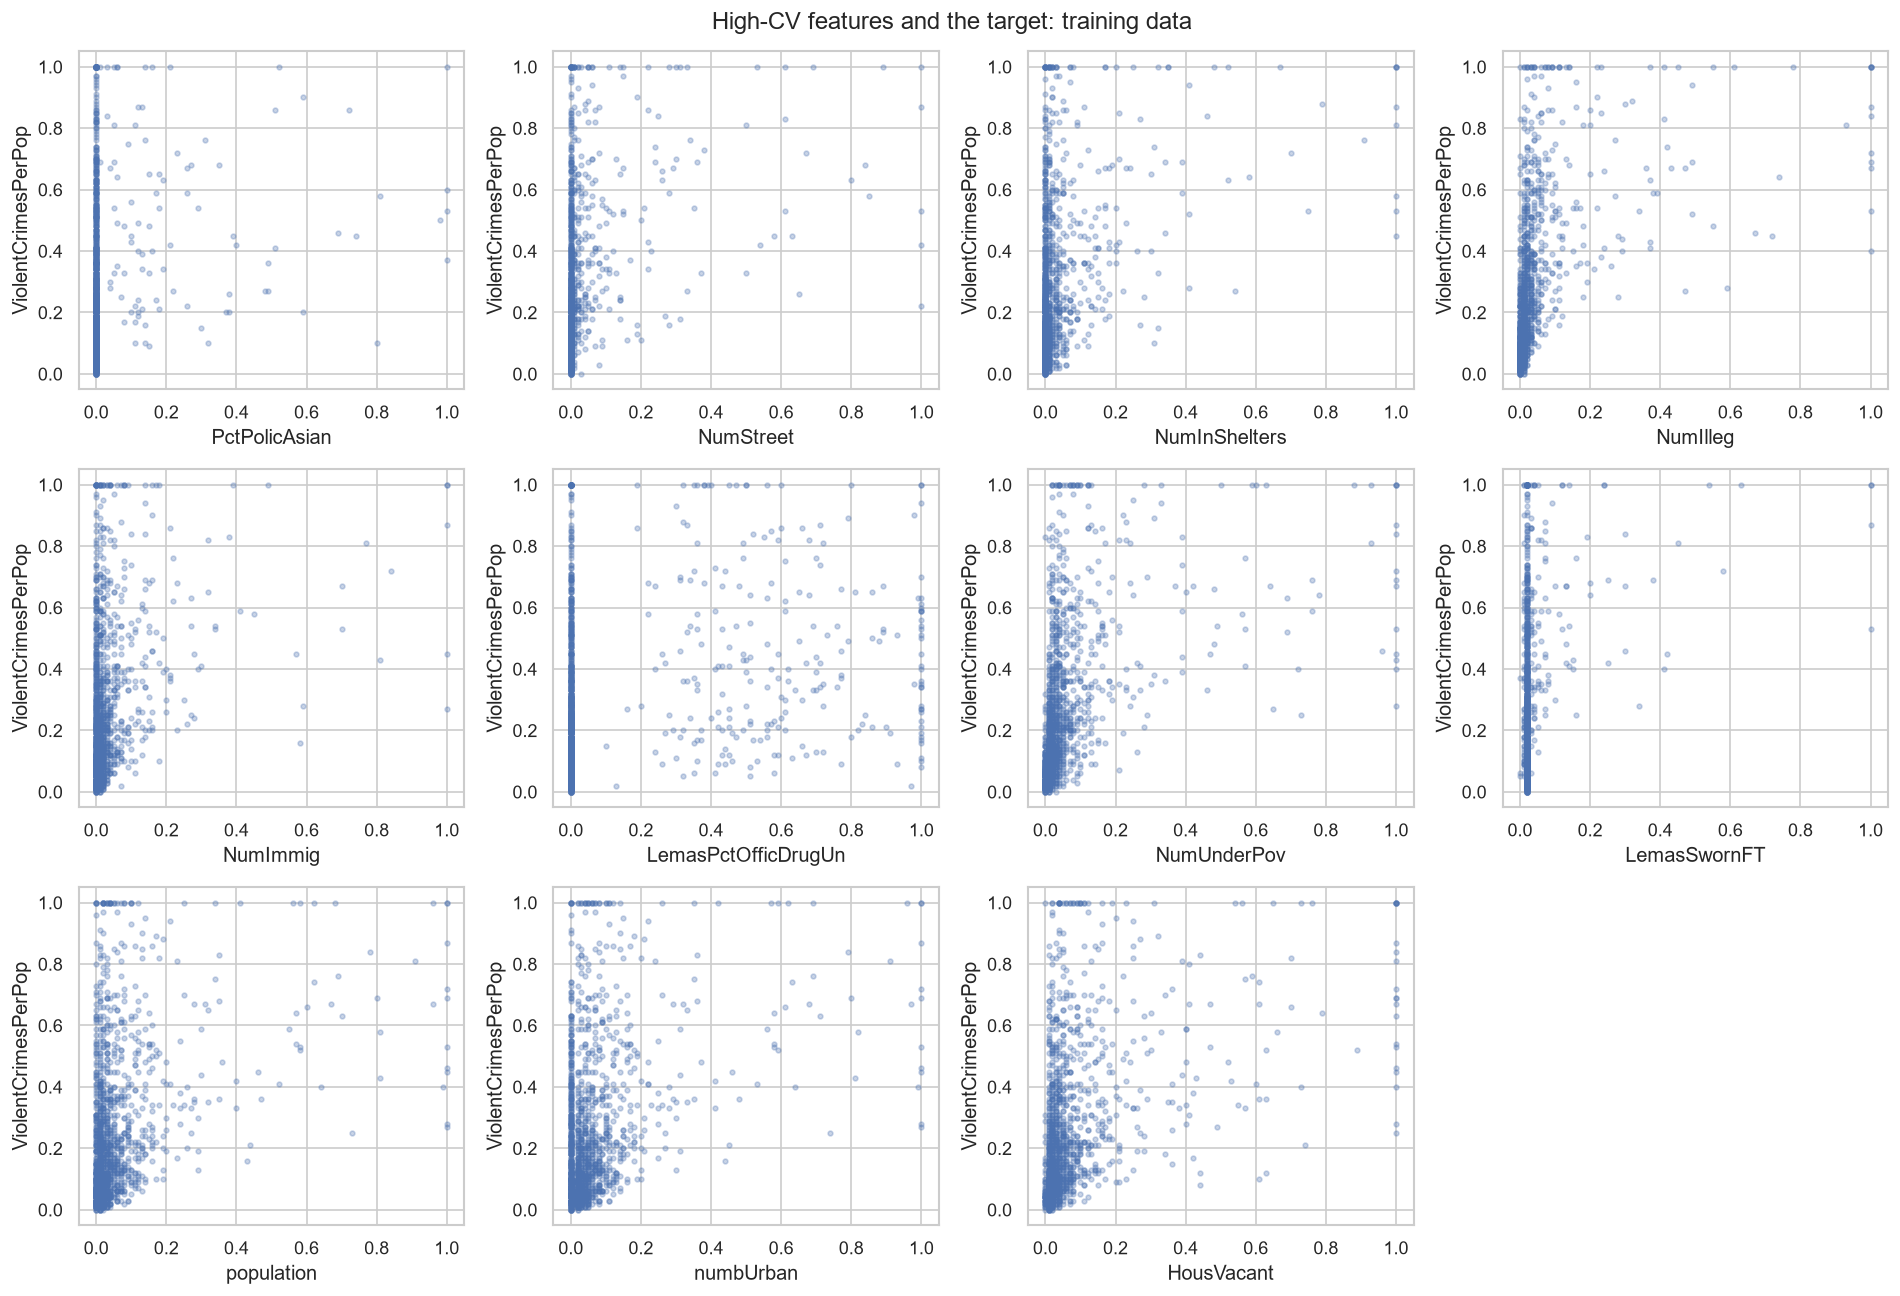

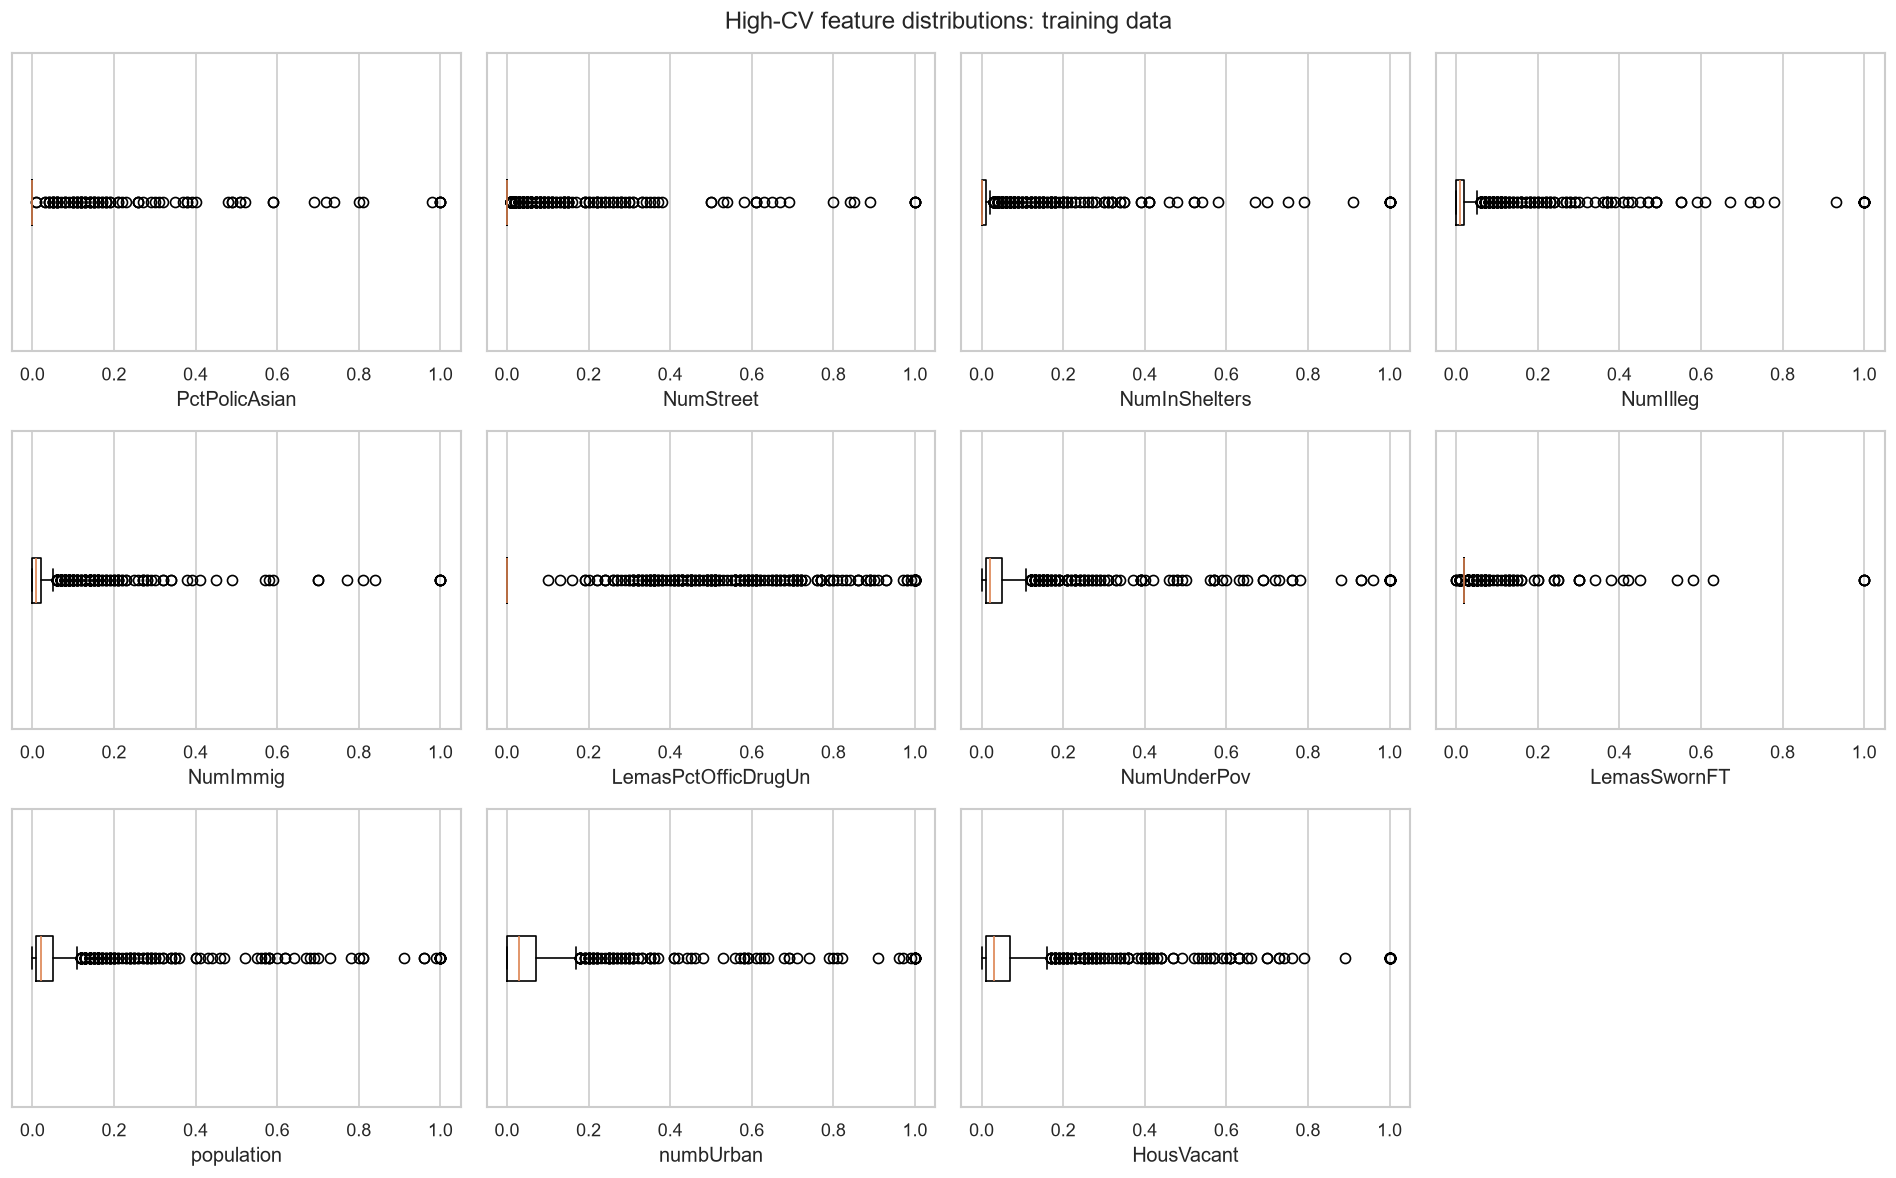

In [9]:
number_selected = int(np.sqrt(128))
top_features = cv_table.head(number_selected).index.tolist()
display(cv_table.loc[top_features].round(6))

fig, axes = plt.subplots(3, 4, figsize=(16, 11))
for ax, feature in zip(axes.flat, top_features):
    ax.scatter(X_train_filled[feature], y_train, s=8, alpha=0.3)
    ax.set_xlabel(feature)
    ax.set_ylabel(target)
for ax in list(axes.flat)[len(top_features):]:
    ax.set_visible(False)
fig.suptitle('High-CV features and the target: training data')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, feature in zip(axes.flat, top_features):
    ax.boxplot(X_train_filled[feature], orientation='horizontal')
    ax.set_xlabel(feature)
    ax.set_yticks([])
for ax in list(axes.flat)[len(top_features):]:
    ax.set_visible(False)
fig.suptitle('High-CV feature distributions: training data')
plt.tight_layout()
plt.show()

Most values are near zero with long upper tails. High CV does not mean strong predictive power.

### 2(f). Least squares

Test error = MSE throughout. Lower is better.

In [10]:
ols = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', LinearRegression())
])
ols.fit(X_train, y_train)
ols_mse = mean_squared_error(y_test, ols.predict(X_test))
results.append({'Model': 'Least squares', 'Test MSE': ols_mse})
print(f'Test MSE: {ols_mse:.6f}')

Test MSE: 0.017966


### 2(g). Ridge regression

Five-fold CV chooses lambda (alpha). Keep the original 0-1 feature scale.

In [11]:
ridge_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', Ridge())
])
ridge_search = GridSearchCV(
    ridge_pipeline, {'model__alpha': np.logspace(-4, 4, 33)},
    scoring='neg_mean_squared_error', cv=cv, n_jobs=1
)
ridge_search.fit(X_train, y_train)
ridge_mse = mean_squared_error(y_test, ridge_search.predict(X_test))
results.append({'Model': 'Ridge', 'Test MSE': ridge_mse})
print(f'Best lambda: {ridge_search.best_params_["model__alpha"]:.6g}')
print(f'Best CV MSE: {-ridge_search.best_score_:.6f}')
print(f'Test MSE: {ridge_mse:.6f}')

Best lambda: 3.16228
Best CV MSE: 0.019422
Test MSE: 0.017479


### 2(h). LASSO with and without standardization

Five-fold CV chooses lambda separately. Scaling is fitted inside each training fold.
Nonzero coefficients select features.

In [12]:
lasso_models = {}
lasso_features = {}
lasso_rows = []

for label, standardize in [('LASSO', False), ('LASSO standardized', True)]:
    steps = [('imputer', SimpleImputer(strategy='median'))]
    if standardize:
        steps.append(('scaler', StandardScaler()))
    steps.append(('model', Lasso(max_iter=50000, tol=0.0001)))
    search = GridSearchCV(
        Pipeline(steps), {'model__alpha': np.logspace(-5, -1, 33)},
        scoring='neg_mean_squared_error', cv=cv, n_jobs=1
    )
    search.fit(X_train, y_train)
    mse = mean_squared_error(y_test, search.predict(X_test))
    coefficients = search.best_estimator_.named_steps['model'].coef_
    selected = X_train.columns[np.abs(coefficients) > 0.00000001].tolist()
    lasso_models[label] = search
    lasso_features[label] = selected
    lasso_rows.append({
        'Model': label, 'lambda': search.best_params_['model__alpha'],
        'CV MSE': -search.best_score_, 'Test MSE': mse,
        'Selected features': len(selected)
    })
    results.append({'Model': label, 'Test MSE': mse})
    print(label)
    print('Selected features:', len(selected))
    print(', '.join(selected))
    print()

lasso_results = pd.DataFrame(lasso_rows)
display(lasso_results.round(6))
lower_lasso = lasso_results.loc[lasso_results['Test MSE'].idxmin(), 'Model']
print(f'{lower_lasso} has the lower test MSE in this split.')

LASSO
Selected features: 76
racepctblack, racePctAsian, agePct12t21, agePct12t29, pctUrban, pctWWage, pctWFarmSelf, pctWInvInc, pctWSocSec, pctWPubAsst, pctWRetire, whitePerCap, blackPerCap, indianPerCap, AsianPerCap, OtherPerCap, HispPerCap, PctPopUnderPov, PctLess9thGrade, PctEmploy, PctEmplManu, PctOccupManu, MalePctDivorce, MalePctNevMarr, FemalePctDiv, PctKids2Par, PctYoungKids2Par, PctTeen2Par, PctWorkMom, NumIlleg, PctIlleg, NumImmig, PctImmigRecent, PctImmigRec5, PctImmigRec10, PctRecImmig10, PctNotSpeakEnglWell, PctLargHouseOccup, PersPerOccupHous, PctPersOwnOccup, PctPersDenseHous, PctHousLess3BR, MedNumBR, HousVacant, PctHousOccup, PctVacantBoarded, PctVacMore6Mos, MedYrHousBuilt, PctHousNoPhone, PctWOFullPlumb, OwnOccLowQuart, RentLowQ, MedRent, MedRentPctHousInc, MedOwnCostPctInc, MedOwnCostPctIncNoMtg, NumInShelters, NumStreet, PctForeignBorn, PctBornSameState, PctSameCity85, LemasSwFTFieldPerPop, PolicReqPerOffic, RacialMatchCommPol, PctPolicBlack, PctPolicHisp, PctPolic

,Model,lambda,CV MSE,Test MSE,Selected features
0,LASSO,0.000133,0.019524,0.017604,76
1,LASSO standardized,0.000562,0.019668,0.017749,75


LASSO has the lower test MSE in this split.


### 2(i). Principal component regression (PCR)

Five-fold CV tests M=1,...,122. Imputation, scaling, and PCA stay inside each training fold.

Best M: 60
Best CV MSE: 0.020210
Test MSE: 0.018350


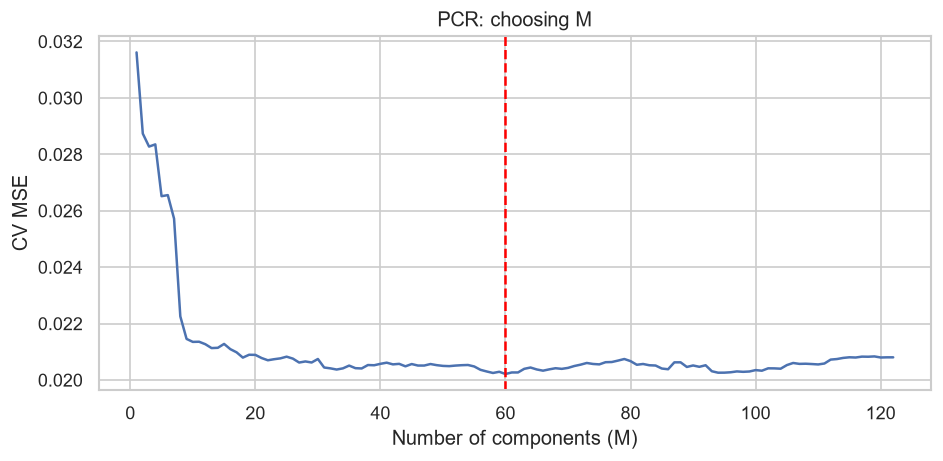

In [13]:
pcr_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('pca', PCA(svd_solver='full')),
    ('model', LinearRegression())
])
pcr_search = GridSearchCV(
    pcr_pipeline,
    {'pca__n_components': list(range(1, X_train.shape[1] + 1))},
    scoring='neg_mean_squared_error', cv=cv, n_jobs=1
)
pcr_search.fit(X_train, y_train)
pcr_mse = mean_squared_error(y_test, pcr_search.predict(X_test))
results.append({'Model': 'PCR', 'Test MSE': pcr_mse})
print('Best M:', pcr_search.best_params_['pca__n_components'])
print(f'Best CV MSE: {-pcr_search.best_score_:.6f}')
print(f'Test MSE: {pcr_mse:.6f}')

plt.figure(figsize=(8, 4))
plt.plot(
    pcr_search.cv_results_['param_pca__n_components'].astype(int),
    -pcr_search.cv_results_['mean_test_score']
)
plt.axvline(pcr_search.best_params_['pca__n_components'], color='red', linestyle='--')
plt.xlabel('Number of components (M)')
plt.ylabel('CV MSE')
plt.title('PCR: choosing M')
plt.tight_layout()
plt.show()

### 2(j). L1-regularized boosting

Five-fold CV chooses XGBoost reg_alpha, the L1 penalty on leaf weights.
Leaves are constants, not LASSO models.

In [14]:
xgb_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', XGBRegressor(
        objective='reg:squarederror', booster='gbtree',
        n_estimators=300, max_depth=3, learning_rate=0.05,
        reg_lambda=0, tree_method='hist', n_jobs=1, random_state=42
    ))
])
xgb_search = GridSearchCV(
    xgb_pipeline,
    {'model__reg_alpha': [0, 0.0001, 0.001, 0.01, 0.1, 1, 10, 100]},
    scoring='neg_mean_squared_error', cv=cv, n_jobs=1
)
xgb_search.fit(X_train, y_train)
xgb_mse = mean_squared_error(y_test, xgb_search.predict(X_test))
results.append({'Model': 'L1 XGBoost', 'Test MSE': xgb_mse})
print('Best alpha:', xgb_search.best_params_['model__reg_alpha'])
print(f'Best CV MSE: {-xgb_search.best_score_:.6f}')
print(f'Test MSE: {xgb_mse:.6f}')
xgb_cv_results = pd.DataFrame({
    'alpha': xgb_search.cv_results_['param_model__reg_alpha'],
    'CV MSE': -xgb_search.cv_results_['mean_test_score']
})
display(xgb_cv_results)

Best alpha: 1
Best CV MSE: 0.020075
Test MSE: 0.016703


,alpha,CV MSE
0,0.0000,0.020646
1,0.0001,0.020640
2,0.0010,0.020960
3,0.0100,0.020670
4,0.1000,0.020145
5,1.0000,0.020075
6,10.0000,0.021925
7,100.0000,0.056606


### 2(f)–2(j). Test error comparison

In [15]:
comparison = pd.DataFrame(results).sort_values('Test MSE').reset_index(drop=True)
display(comparison.round(6))
print(f'Lowest test MSE: {comparison.loc[0, "Model"]}.')

,Model,Test MSE
0,L1 XGBoost,0.016703
1,Ridge,0.017479
2,LASSO,0.017604
3,LASSO standardized,0.017749
4,Least squares,0.017966
5,PCR,0.018350


Lowest test MSE: L1 XGBoost.
